# Custom Reaction Networks in Monod

This notebook demonstrates the `ReactionNetwork` module, which lets you define
arbitrary biological noise models via a reaction-string syntax and have the required
CME log-PGF equations derived automatically.

## Syntax at a glance

```
"0 -> B x U -> S -> 0"
```

* Reactions are separated by **`->`** (chain) or **`;`** (independent).
* `0` is the empty set (source / sink).
* `B x U` — capital-letter prefix → **geometric burst** of mean B.
* `2 x U` — integer prefix → **deterministic burst** of size 2.
* `A + B` — multi-species nodes (products or reactants).

Parameters are ordered: **named burst-size params first, then one rate per `→`**,
all in log₁₀ scale (matching the rest of monod).

## Contents

1. Parsing and introspection  
2. Recovering the built-in **Bursty** model  
3. Adding a secondary degradation pathway (`; U -> 0`)  
4. Catalytic protein production (`S -> S + P`)  
5. Constitutive model from scratch  
6. Burst-size sweep  
7. Model selection: which network best fits real data?  
8. Is the network identifiable? Structural checks, a numerical rank test, and standard-error flags  
9. Time-delayed reactions (`=>`): what a delay changes, and whether the data can see it

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import sys, os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from monod.reaction_network import ReactionNetwork
from monod.cme_toolbox import CMEModel
os.makedirs('figures', exist_ok=True)

In [3]:
# ── Shared plotting helper ───────────────────────────────────────────────────

def plot_joint(pss, title, xlabel='Species 0', ylabel='Species 1', cmap='Blues', save_path=None):
    """Joint PMF heatmap with marginal line plots."""
    fig = plt.figure(figsize=(6, 5))
    gs  = fig.add_gridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4],
                           hspace=0.05, wspace=0.05)
    ax_j = fig.add_subplot(gs[1, 0])
    ax_t = fig.add_subplot(gs[0, 0], sharex=ax_j)
    ax_r = fig.add_subplot(gs[1, 1], sharey=ax_j)

    im = ax_j.imshow(pss.T, origin='lower', aspect='auto', cmap=cmap,
                     norm=mcolors.PowerNorm(gamma=0.4, vmin=0))
    ax_j.set_xlabel(xlabel, fontsize=11)
    ax_j.set_ylabel(ylabel, fontsize=11)

    m0 = pss.sum(axis=1); m1 = pss.sum(axis=0)
    ax_t.plot(m0, color='steelblue', lw=1.5)
    ax_t.fill_between(range(len(m0)), m0, alpha=0.3, color='steelblue')
    ax_t.set_ylabel('P(0)', fontsize=9)
    ax_r.plot(m1, range(len(m1)), color='salmon', lw=1.5)
    ax_r.fill_betweenx(range(len(m1)), m1, alpha=0.3, color='salmon')
    ax_r.set_xlabel('P(1)', fontsize=9)

    plt.setp(ax_t.get_xticklabels(), visible=False)
    plt.setp(ax_r.get_yticklabels(), visible=False)
    fig.suptitle(title, fontsize=11, y=1.01)
    plt.colorbar(im, ax=[ax_j, ax_r], label='Probability', shrink=0.8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


def marginals(pss):
    """Return (m0, m1) marginal arrays."""
    return pss.sum(axis=1), pss.sum(axis=0)


def mean_counts(pss):
    """Return (E[n0], E[n1])."""
    idx0 = np.arange(pss.shape[0])
    idx1 = np.arange(pss.shape[1])
    return (pss * idx0[:, None]).sum(), (pss * idx1[None, :]).sum()

---
## 1 · Parsing and introspection

Instantiating a `ReactionNetwork` parses the string and extracts:
* **species** — in order of first appearance.
* **named_params** — geometric burst-size parameters.
* **rate_names** — one rate constant per `→`.
* **all_params** — the full parameter vector (log₁₀ scale).

In [4]:
networks = {
    'Bursty equivalent'          : '0 -> B x U -> S -> 0',
    'Bursty + U degradation'     : '0 -> B x U -> S -> 0; U -> 0',
    'Constitutive equivalent'    : '0 -> U -> S -> 0',
    'Deterministic burst of 3'   : '0 -> 3 x U -> S -> 0',
    'Catalytic protein model'    : '0 -> B x U -> S -> 0; S -> S + P; P -> 0',
}

for label, net_str in networks.items():
    net = ReactionNetwork(net_str)
    print(f'{label}')
    print(f'  network    : {net_str}')
    print(f'  species    : {net.species}')
    print(f'  all_params : {net.all_params}')
    print()

Bursty equivalent
  network    : 0 -> B x U -> S -> 0
  species    : ['U', 'S']
  all_params : ['B', 'k0', 'k1', 'k2']

Bursty + U degradation
  network    : 0 -> B x U -> S -> 0; U -> 0
  species    : ['U', 'S']
  all_params : ['B', 'k0', 'k1', 'k2', 'k3']

Constitutive equivalent
  network    : 0 -> U -> S -> 0
  species    : ['U', 'S']
  all_params : ['k0', 'k1', 'k2']

Deterministic burst of 3
  network    : 0 -> 3 x U -> S -> 0
  species    : ['U', 'S']
  all_params : ['k0', 'k1', 'k2']

Catalytic protein model
  network    : 0 -> B x U -> S -> 0; S -> S + P; P -> 0
  species    : ['U', 'S', 'P']
  all_params : ['B', 'k0', 'k1', 'k2', 'k3', 'k4']



The `repr` of a `ReactionNetwork` shows the parsed reaction list with clear notation:

In [5]:
print(ReactionNetwork('0 -> B x U -> S -> 0; S -> S + P; P -> 0'))

ReactionNetwork('0 -> B x U -> S -> 0; S -> S + P; P -> 0')
  species    : ['U', 'S', 'P']
  all_params : ['B', 'k0', 'k1', 'k2', 'k3', 'k4']
  reactions  :
    ∅ →(k0) U  [geometric B]
    U →(k1) S
    S →(k2) ∅
    S →(k3) S + P
    P →(k4) ∅


---
## 2 · Recovering the built-in Bursty model

The string `"0 -> B x U -> S -> 0"` encodes three reactions:

| Reaction | Rate | PGF contribution |
|----------|------|------------------|
| $\emptyset \to \text{Geo}(B)\times U$ | $k_0$ | $d\phi/dt \mathrel{+}= k_0 B u_U / (1 - B u_U)$ |
| $U \to S$ | $k_1$ | $du_U/dt \mathrel{+}= k_1(u_S - u_U)$ |
| $S \to \emptyset$ | $k_2$ | $du_S/dt \mathrel{+}= -k_2 u_S$ |

Setting `normalize_production_rate=True` fixes $k_0 = 1$, making the parameter
vector $[B, k_1, k_2]$ identical to the built-in Bursty model $[b, \beta, \gamma]$.

In [6]:
B, beta, gamma = 3.0, 0.4, 0.25
LIMITS = [60, 80]

# ── Built-in Bursty ──────────────────────────────────────────────────────────
m_builtin = CMEModel('Bursty', 'None')
pss_ref   = m_builtin.eval_model_pss(np.log10([B, beta, gamma]), LIMITS)

# ── Custom equivalent (normalize_production_rate=True drops k0 from params) ─
m_custom = CMEModel(
    'Custom', 'None',
    network='0 -> B x U -> S -> 0',
    normalize_production_rate=True,
)
print('Custom param vector:', m_custom.network.all_params)   # [B, k1, k2]
pss_custom = m_custom.eval_model_pss(np.log10([B, beta, gamma]), LIMITS)

# ── Quantitative comparison ──────────────────────────────────────────────────
mask   = pss_ref > 0
kld    = np.sum(pss_ref[mask] * np.log(pss_ref[mask] / np.clip(pss_custom[mask], 1e-15, None)))
eu_ref,  es_ref  = mean_counts(pss_ref)
eu_cust, es_cust = mean_counts(pss_custom)

print(f'\nKL(Bursty ∥ Custom) = {kld:.4f}  (< 0.01 is excellent)')
print(f'E[U]  Bursty={eu_ref:.3f}  Custom={eu_cust:.3f}')
print(f'E[S]  Bursty={es_ref:.3f}  Custom={es_cust:.3f}')

Custom param vector: ['B', 'k1', 'k2']

KL(Bursty ∥ Custom) = 0.0000  (< 0.01 is excellent)
E[U]  Bursty=7.500  Custom=7.500
E[S]  Bursty=12.000  Custom=12.000


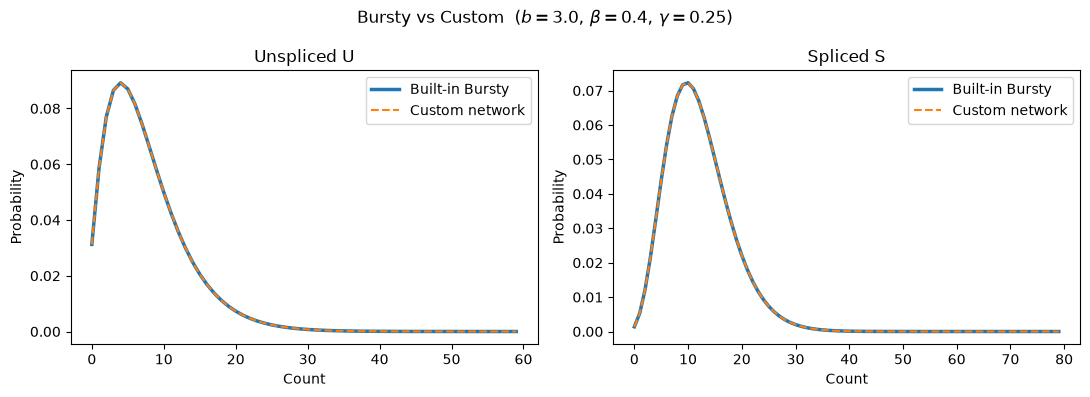

In [7]:
# Side-by-side marginal comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
m0_ref,  m1_ref  = marginals(pss_ref)
m0_cust, m1_cust = marginals(pss_custom)

for ax, m_ref, m_cust, label in [
    (axes[0], m0_ref, m0_cust, 'Unspliced U'),
    (axes[1], m1_ref, m1_cust, 'Spliced S'),
]:
    ax.plot(m_ref,  lw=2.5, label='Built-in Bursty')
    ax.plot(m_cust, lw=1.5, ls='--', label='Custom network')
    ax.set_xlabel('Count'); ax.set_ylabel('Probability')
    ax.set_title(label); ax.legend()

fig.suptitle(
    rf'Bursty vs Custom  ($b={B},\,\beta={beta},\,\gamma={gamma}$)',
    fontsize=12
)
plt.savefig('figures/network_bursty_recovery.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

The two marginals are essentially indistinguishable — the Custom model correctly
recovers the built-in implementation.

---
## 3 · Adding a secondary degradation pathway

The semicolon syntax appends an independent reaction to the network.

```python
"0 -> B x U -> S -> 0; U -> 0"
```

adds $U \to \emptyset$ at rate $k_3$, giving unspliced mRNA **two exit routes**
(splicing at rate $k_1$ _or_ direct degradation at rate $k_3$).
This raises the effective clearance rate of $U$ and reduces $E[U]$ while
leaving $E[S]$ largely unchanged.

In [8]:
net_extra = ReactionNetwork('0 -> B x U -> S -> 0; U -> 0')
print(net_extra)
print('\nall_params:', net_extra.all_params)  # B, k0 (burst rate), k1 (β), k2 (γ), k3 (γ_U)

ReactionNetwork('0 -> B x U -> S -> 0; U -> 0')
  species    : ['U', 'S']
  all_params : ['B', 'k0', 'k1', 'k2', 'k3']
  reactions  :
    ∅ →(k0) U  [geometric B]
    U →(k1) S
    S →(k2) ∅
    U →(k3) ∅

all_params: ['B', 'k0', 'k1', 'k2', 'k3']


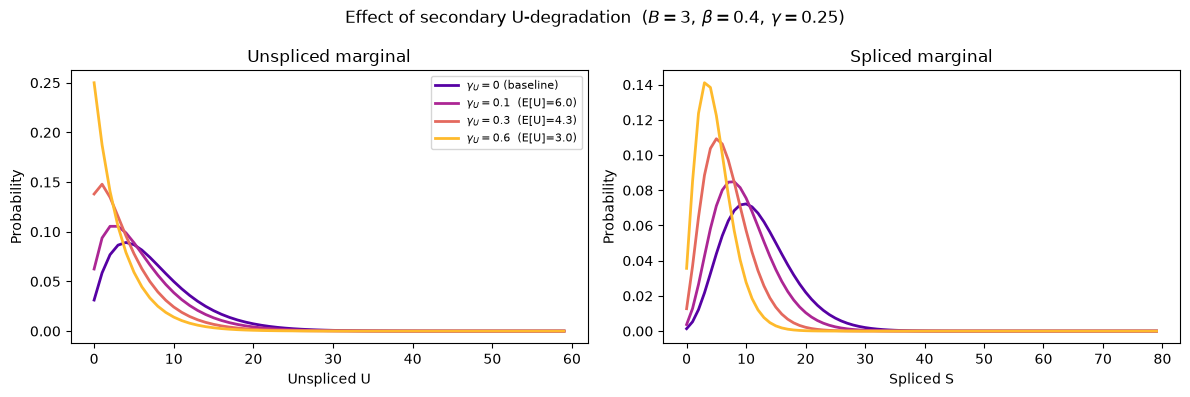

In [9]:
B, beta, gamma = 3.0, 0.4, 0.25
LIMITS = [60, 80]

# Baseline: Bursty without extra degradation (normalize k0=1)
m_base = CMEModel('Custom', 'None',
                  network='0 -> B x U -> S -> 0',
                  normalize_production_rate=True)
pss_base = m_base.eval_model_pss(np.log10([B, beta, gamma]), LIMITS)

# Vary extra U degradation rate gamma_U
gamma_U_vals = [0.0, 0.1, 0.3, 0.6]

m_extra = CMEModel('Custom', 'None',
                   network='0 -> B x U -> S -> 0; U -> 0',
                   normalize_production_rate=True)
# params order: [B, k1=beta, k2=gamma, k3=gamma_U]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(gamma_U_vals)))

for gamma_U, col in zip(gamma_U_vals, colors):
    if gamma_U == 0.0:
        pss = pss_base
        lbl = r'$\gamma_U = 0$ (baseline)'
    else:
        p = np.log10([B, beta, gamma, gamma_U])
        pss = m_extra.eval_model_pss(p, LIMITS)
        eu, es = mean_counts(pss)
        lbl = rf'$\gamma_U = {gamma_U}$  (E[U]={eu:.1f})'

    m0, m1 = marginals(pss)
    eu, es = mean_counts(pss)
    axes[0].plot(m0, color=col, lw=2, label=lbl)
    axes[1].plot(m1, color=col, lw=2)

axes[0].set_xlabel('Unspliced U'); axes[0].set_ylabel('Probability')
axes[0].set_title('Unspliced marginal'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('Spliced S'); axes[1].set_ylabel('Probability')
axes[1].set_title('Spliced marginal')

fig.suptitle(
    r'Effect of secondary U-degradation  ($B=3,\,\beta=0.4,\,\gamma=0.25$)',
    fontsize=12
)
plt.savefig('figures/network_extra_degradation.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

Adding $U \to \emptyset$ compresses the unspliced distribution toward zero while
leaving the spliced marginal nearly unchanged — exactly the expected phenomenology.

---
## 4 · Catalytic protein production

The reaction `S -> S + P` means spliced mRNA **catalyses** production of protein P
without being consumed.  Its propensity is $k \cdot n_S$ (first-order in $n_S$),
but the characteristic ODE gains a **nonlinear** term:

$$\frac{du_S}{dt} \mathrel{+}= k_2 \, u_P \, (1 + u_S)$$

With bursty transcription, splicing and mRNA decay around it this is exactly the
ProteinBursty model, so we can compare directly. (Without `S -> 0` the spliced
count would grow without bound; section 8 shows how monod points that out.)

In [10]:
net_prot = ReactionNetwork('0 -> B x U -> S -> 0; S -> S + P; P -> 0')
print(net_prot)
print('\nall_params:', net_prot.all_params)
# [B, k0 (burst rate), k1 (β), k2 (γ), k3 (k_p catalytic), k4 (γ_p)]


ReactionNetwork('0 -> B x U -> S -> 0; S -> S + P; P -> 0')
  species    : ['U', 'S', 'P']
  all_params : ['B', 'k0', 'k1', 'k2', 'k3', 'k4']
  reactions  :
    ∅ →(k0) U  [geometric B]
    U →(k1) S
    S →(k2) ∅
    S →(k3) S + P
    P →(k4) ∅

all_params: ['B', 'k0', 'k1', 'k2', 'k3', 'k4']


In [11]:
# The ProteinBursty-equivalent network:
#   0 -> B x U  (bursty transcription)
#   U -> S       (splicing, rate beta)
#   S -> 0       (mRNA degradation, rate gamma_s)
#   S -> S + P   (catalytic protein production, rate k_p)
#   P -> 0       (protein degradation, rate gamma_p)
#
# Three-species networks run on the Rust kernel like two-species ones; the grid
# is kept small only so the joint distribution plots stay readable.
NETWORK_PROT = '0 -> B x U -> S -> 0; S -> S + P; P -> 0'
B_p, beta_p, gamma_s, k_p, gamma_p = 2.0, 1.5, 1.0, 1.2, 0.8
LIMITS_3D = [12, 12, 20]

m_prot = CMEModel(
    'Custom', 'None',
    network=NETWORK_PROT,
    normalize_production_rate=True,
)
print('Network:', NETWORK_PROT)
print('Custom params:', m_prot.network.all_params)
# [B, k1(beta), k2(gamma_s), k3(k_p), k4(gamma_p)]

p_prot = np.log10([B_p, beta_p, gamma_s, k_p, gamma_p])
pss_3d = m_prot.eval_model_pss(p_prot, LIMITS_3D)
print('PSS shape:', pss_3d.shape, ' (U x S x P)')
print('PSS sum:  ', round(pss_3d.sum(), 6))

Network: 0 -> B x U -> S -> 0; S -> S + P; P -> 0
Custom params: ['B', 'k1', 'k2', 'k3', 'k4']
PSS shape: (12, 12, 20)  (U x S x P)
PSS sum:   1.0


E[U] = 1.29,  E[S] = 1.97,  E[P] = 2.99


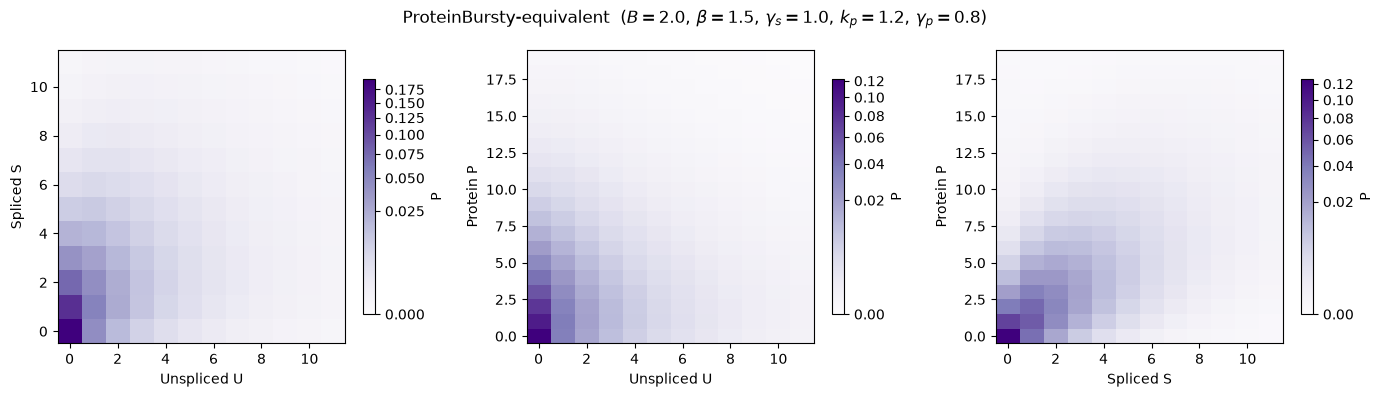

In [12]:
# Marginalise to 2D projections for visualisation
pss_US = pss_3d.sum(axis=2)   # U × S
pss_UP = pss_3d.sum(axis=1)   # U × P
pss_SP = pss_3d.sum(axis=0)   # S × P

eu, es, ep = [
    (pss_3d * np.arange(pss_3d.shape[i])[
        tuple(slice(None) if j == i else np.newaxis for j in range(3))
    ]).sum()
    for i in range(3)
]
print(f'E[U] = {eu:.2f},  E[S] = {es:.2f},  E[P] = {ep:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, pss2, xl, yl in [
    (axes[0], pss_US, 'Unspliced U', 'Spliced S'),
    (axes[1], pss_UP, 'Unspliced U', 'Protein P'),
    (axes[2], pss_SP, 'Spliced S',   'Protein P'),
]:
    im = ax.imshow(pss2.T, origin='lower', aspect='auto', cmap='Purples',
                   norm=mcolors.PowerNorm(gamma=0.4, vmin=0))
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    plt.colorbar(im, ax=ax, label='P', shrink=0.8)

fig.suptitle(
    rf'ProteinBursty-equivalent  ($B={B_p},\,\beta={beta_p},\,\gamma_s={gamma_s},\,k_p={k_p},\,\gamma_p={gamma_p}$)',
    fontsize=12
)
plt.savefig('figures/network_protein_3d.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

---
## 5 · Constitutive model from scratch

`"0 -> U -> S -> 0"` has no burst parameter — production is deterministic
(one molecule at a time), so both marginals are Poisson.

The parameter vector is `[k0, k1, k2]` — three rates, no named burst parameter.

all_params: ['k0', 'k1', 'k2']
E[U] = 2.500  (expected 2.500)
E[S] = 4.000  (expected 4.000)


/tmp/ipykernel_1999901/838273831.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


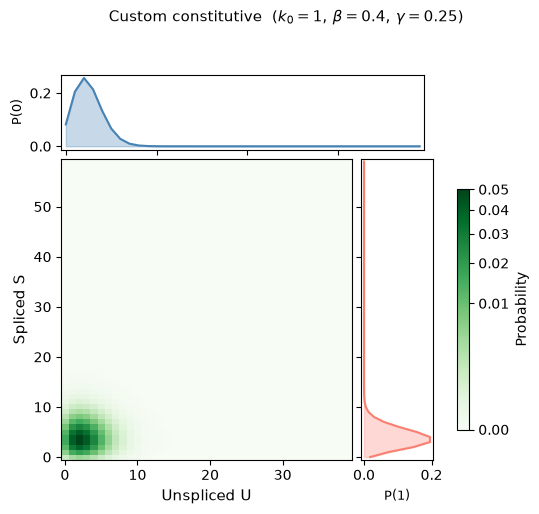

In [13]:
net_const = ReactionNetwork('0 -> U -> S -> 0')
print('all_params:', net_const.all_params)   # [k0, k1, k2]  — no named param

# k0=1 (prod rate), k1=0.4 (β), k2=0.25 (γ)  →  Poisson(mean = k0/k1 = 2.5)
m_const = CMEModel('Custom', 'None', network='0 -> U -> S -> 0')
p_const  = np.log10([1.0, 0.4, 0.25])   # [k0, k1, k2]
pss_const = m_const.eval_model_pss(p_const, [40, 60])

eu_c, es_c = mean_counts(pss_const)
print(f'E[U] = {eu_c:.3f}  (expected {1.0/0.4:.3f})')
print(f'E[S] = {es_c:.3f}  (expected {1.0/0.25:.3f})')

plot_joint(pss_const,
           r'Custom constitutive  ($k_0=1,\,\beta=0.4,\,\gamma=0.25$)',
           xlabel='Unspliced U', ylabel='Spliced S', cmap='Greens')

---
## 6 · Burst-size sweep — geometric vs deterministic

We compare two ways to produce molecules in groups:

* **`B x U`** (capital letter) — burst size **geometrically distributed** with mean $B$.
* **`n x U`** (integer) — burst size **exactly** $n$ (deterministic).

At matched mean burst size, the geometric distribution produces heavier tails.

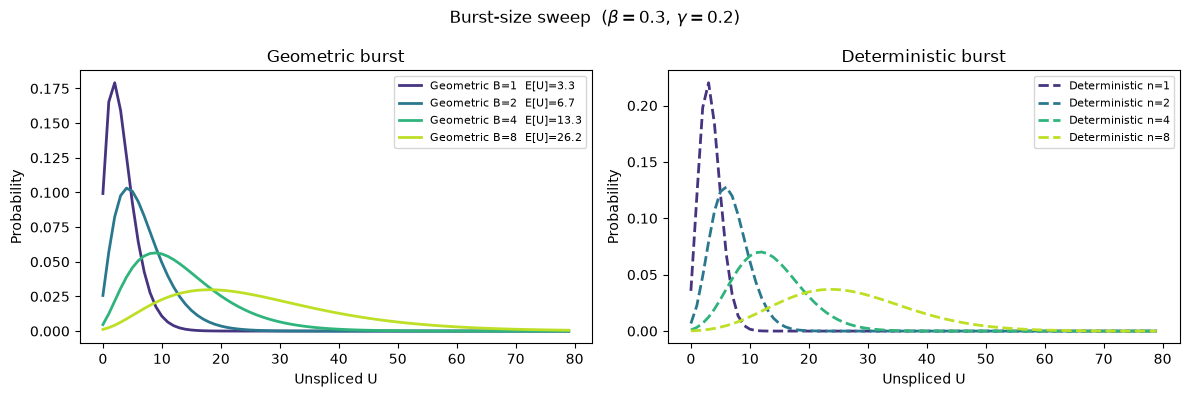

In [14]:
burst_means = [1, 2, 4, 8]
beta_sw, gamma_sw = 0.3, 0.2
LIMITS_SW = [80, 100]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(burst_means)))

for b_mean, col in zip(burst_means, colors):
    # Geometric burst (named B)
    m_geo = CMEModel('Custom', 'None',
                     network='0 -> B x U -> S -> 0',
                     normalize_production_rate=True)
    pss_geo = m_geo.eval_model_pss(np.log10([b_mean, beta_sw, gamma_sw]), LIMITS_SW)

    # Deterministic burst (integer literal)
    n_det = max(1, int(round(b_mean)))
    m_det = CMEModel('Custom', 'None',
                     network=f'0 -> {n_det} x U -> S -> 0')
    # params: [k0, k1, k2]  (no named param)
    pss_det = m_det.eval_model_pss(np.log10([1.0, beta_sw, gamma_sw]), LIMITS_SW)

    eu_g, _ = mean_counts(pss_geo)
    m0_g, _ = marginals(pss_geo)
    m0_d, _ = marginals(pss_det)

    axes[0].plot(m0_g, color=col, lw=2,     label=f'Geometric B={b_mean}  E[U]={eu_g:.1f}')
    axes[1].plot(m0_d, color=col, lw=2, ls='--', label=f'Deterministic n={n_det}')

for ax, title in zip(axes, ['Geometric burst', 'Deterministic burst']):
    ax.set_xlabel('Unspliced U'); ax.set_ylabel('Probability')
    ax.set_title(title); ax.legend(fontsize=8)

fig.suptitle(
    rf'Burst-size sweep  ($\beta={beta_sw},\,\gamma={gamma_sw}$)',
    fontsize=12
)
plt.savefig('figures/network_burst_sweep.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

Geometric bursts produce broader, heavier-tailed distributions than deterministic
bursts of the same size — a direct consequence of the extra stochasticity in burst size.

---
## 7 · Model selection on real data

We load the bundled example dataset and compare three networks on gene **PTPRC**:

| Model | Network string | Parameters |
|-------|---------------|------------|
| Bursty (built-in) | — | $b, \beta, \gamma$ |
| Bursty + U decay | `0 -> B x U -> S -> 0; U -> 0` | $B, \beta, \gamma, \gamma_U$ |
| Constitutive | `0 -> U -> S -> 0` | $k_0, \beta, \gamma$ |

We fit each by minimising KL-divergence starting from method-of-moments estimates.

In [15]:
import anndata as ad
from monod.extract_data import extract_data, make_histogram
from scipy.optimize import minimize

# ── Load data ────────────────────────────────────────────────────────────────
EXAMPLE_PATH = os.path.join("example_h5ad", "example_adata.h5ad")
raw_adata = ad.read_h5ad(EXAMPLE_PATH)

m_ref_bursty = CMEModel("Bursty", "None")
proc_adata = extract_data(
    raw_adata, m_ref_bursty,
    dataset_name="custom_selection_demo",
    n_genes=1, viz=False, hist_type="unique",
)

M_raw = proc_adata.uns["M"][:, 0].tolist()
# Cap grid limits so the demo's scipy fits stay quick
M = [min(m, 40) for m in M_raw]

# Unpack histogram and filter out any observations outside the capped limits
hist = make_histogram(proc_adata, "unique", proc_adata.uns["M"])
coords_raw, freqs_raw = hist[0]
mask = np.all(coords_raw < np.array(M)[None, :], axis=1)
coords = coords_raw[mask]
freqs  = freqs_raw[mask]
# Re-normalise to account for truncated observations
freqs  = freqs / freqs.sum()

gene = proc_adata.var_names[0]
print(f"Gene: {gene},  raw limits: {M_raw},  capped limits: {M}")
print(f"Observations retained: {mask.sum()}/{len(mask)} ({100*mask.mean():.1f}%)")


Gene: PTPRC,  raw limits: [81, 44],  capped limits: [40, 40]
Observations retained: 513/562 (91.3%)


In [16]:
# ── Helper: fit a model by KLD minimisation ───────────────────────────────────

def fit_model(model, M, coords, freqs, p0, bounds):
    """L-BFGS-B optimisation of KLD; returns (p_opt, kld_opt)."""
    result = minimize(
        lambda p: model.eval_model_kld(p, M, None, (coords, freqs)),
        x0=p0,
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': 100, 'ftol': 1e-12},
    )
    return result.x, result.fun


# ── 7.1  Built-in Bursty (reference) ────────────────────────────────────────
lb_3 = [-1.0, -1.8, -1.8]
ub_3 = [ 4.2,  2.5,  3.5]

moments = {col: float(proc_adata.var[col].values[0])
           for col in proc_adata.var.columns if col.startswith('MOM_')}
p_mom   = m_ref_bursty.get_MoM(moments, np.array(lb_3), np.array(ub_3), samp=np.zeros(2))

p_bursty_opt, kld_bursty = fit_model(m_ref_bursty, M, coords, freqs, p_mom,
                                      list(zip(lb_3, ub_3)))
print(f'Bursty (built-in)  KLD = {kld_bursty:.5f}  '
      f'params = {np.round(10**p_bursty_opt, 3)}')

Bursty (built-in)  KLD = 0.11910  params = [12.317  9.103 19.614]


In [17]:
# ── 7.2  Custom Bursty + U degradation — fitted ──────────────────────────────
# Custom networks run on the Rust kernel, so a gradient fit costs seconds. The
# integrator's cost does not depend on how far apart the rates are, so the
# parameter box can be as wide as for the built-in models.
import time

m_udeg = CMEModel(
    'Custom', 'None',
    network='0 -> B x U -> S -> 0; U -> 0',
    normalize_production_rate=True,
)
print('Bursty+Udeg params:', m_udeg.network.all_params)   # [B, k1=beta, k2=gamma, k3=gamma_U]

lb_4 = [-1.0, -1.0, -1.0, -1.0]
ub_4 = [ 4.2,  2.0,  2.0,  2.0]
# start from the Bursty optimum with a small extra degradation rate
p0_udeg = np.clip(np.concatenate([p_bursty_opt, [np.log10(0.15)]]), lb_4, ub_4)

t0 = time.time()
res = minimize(
    lambda p: m_udeg.eval_model_kld(p, M, None, (coords, freqs)),
    x0=p0_udeg, method='L-BFGS-B', bounds=list(zip(lb_4, ub_4)),
    options={'maxiter': 30, 'ftol': 1e-10},
)
p_udeg_opt, kld_udeg = res.x, res.fun
print(f'Bursty+Udeg  KLD = {kld_udeg:.5f}  '
      f'params = {np.round(10**p_udeg_opt, 3)}  ({time.time()-t0:.1f} s, {res.nfev} evaluations)')


Bursty+Udeg params: ['B', 'k1', 'k2', 'k3']


Bursty+Udeg  KLD = 0.11255  params = [18.499  3.863 10.307  7.348]  (2.2 s, 190 evaluations)


In [18]:
# ── 7.3  Constitutive — forward eval at Bursty-optimal rates ────────────────
# This network leaves every rate free (no normalisation), which is fine for
# evaluating it at chosen rates but not for fitting: see section 8.
m_con = CMEModel("Custom", "None", network="0 -> U -> S -> 0")
print('Constitutive params:', m_con.network.all_params)   # [k0, k1, k2]

# k0 = beta*B_opt (match mean production), k1 = beta_opt, k2 = gamma_opt
k0_const = 10**p_bursty_opt[1] * 10**p_bursty_opt[0]  # beta * B
p_con_opt = np.log10([k0_const, 10**p_bursty_opt[1], 10**p_bursty_opt[2]])
kld_con = m_con.eval_model_kld(p_con_opt, M, None, (coords, freqs))
print(f'Constitutive  KLD = {kld_con:.5f}  '
      f'params = {np.round(10**p_con_opt, 3)}')


Constitutive params: ['k0', 'k1', 'k2']
Constitutive  KLD = 14.66451  params = [112.128   9.103  19.614]


In [19]:
# ── 7.4  Summary table ───────────────────────────────────────────────────────
print(f'{"Model":<25} {"KLD":>8}  {"n_params":>8}  {"Params (linear)"}')
print('-' * 70)
rows = [
    ('Bursty (built-in)',   kld_bursty, 3, p_bursty_opt),
    ('Bursty + U decay',    kld_udeg,   4, p_udeg_opt),
    ('Constitutive',        kld_con,    3, p_con_opt),
]
for name, kld, n, p in rows:
    vals = ', '.join(f'{v:.3f}' for v in 10**p)
    print(f'{name:<25} {kld:>8.5f}  {n:>8}  [{vals}]')

Model                          KLD  n_params  Params (linear)
----------------------------------------------------------------------
Bursty (built-in)          0.11910         3  [12.317, 9.103, 19.614]
Bursty + U decay           0.11255         4  [18.499, 3.863, 10.307, 7.348]
Constitutive              14.66451         3  [112.128, 9.103, 19.614]


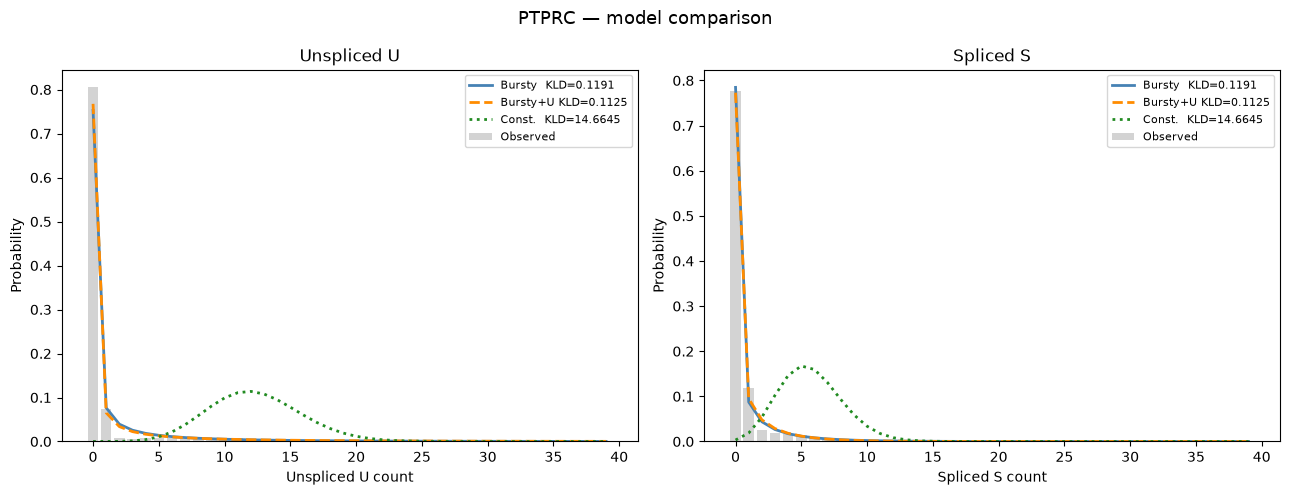

In [20]:
# ── 7.5  Visual comparison ───────────────────────────────────────────────────

# Empirical marginals
obs_u = np.zeros(M[0]); obs_s = np.zeros(M[1])
for (cu, cs), f in zip(coords, freqs):
    if int(cu) < M[0]: obs_u[int(cu)] += f
    if int(cs) < M[1]: obs_s[int(cs)] += f

# Compute fitted PSS for each model
pss_bursty = m_ref_bursty.eval_model_pss(p_bursty_opt, M)
pss_udeg   = m_udeg.eval_model_pss(p_udeg_opt, M)
pss_con    = m_con.eval_model_pss(p_con_opt, M)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, obs, axis, label in [
    (axes[0], obs_u, 1, 'Unspliced U'),
    (axes[1], obs_s, 0, 'Spliced S'),
]:
    ax.bar(range(len(obs)), obs, color='lightgrey', label='Observed', zorder=1)
    for pss, name, ls, col in [
        (pss_bursty, f'Bursty  KLD={kld_bursty:.4f}',  '-',  'steelblue'),
        (pss_udeg,   f'Bursty+U KLD={kld_udeg:.4f}', '--', 'darkorange'),
        (pss_con,    f'Const.  KLD={kld_con:.4f}',    ':',  'forestgreen'),
    ]:
        marg = pss.sum(axis=axis)
        ax.plot(marg, lw=2, ls=ls, color=col, label=name)
    ax.set_xlabel(f'{label} count'); ax.set_ylabel('Probability')
    ax.set_title(label); ax.legend(fontsize=8)

fig.suptitle(f'{gene} — model comparison', fontsize=13)
plt.savefig('figures/network_model_selection.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

The model with the **lowest KLD** is the best fit to this gene's data.

The Constitutive model (no bursting) fits poorly — as expected for a gene with
variance well above the mean.  Bursty+Udecay fits a little better than Bursty; whether
the gain is worth a fourth parameter is a question for the AIC below. With tens of
thousands of cells even a small KLD improvement is significant, so the AIC prefers the
larger model here.

In [21]:
# ── AIC (lower is better) ────────────────────────────────────────────────────
n_cells = proc_adata.n_obs
print('AIC = 2k + 2·n_cells·KLD  (proportional to negative log-likelihood)\n')
for name, kld, n_p, _ in rows:
    aic = 2 * n_p + 2 * n_cells * kld
    print(f'  {name:<25}  n_params={n_p}  KLD={kld:.5f}  AIC={aic:.1f}')

AIC = 2k + 2·n_cells·KLD  (proportional to negative log-likelihood)

  Bursty (built-in)          n_params=3  KLD=0.11910  AIC=15724.0
  Bursty + U decay           n_params=4  KLD=0.11255  AIC=14861.5
  Constitutive               n_params=3  KLD=14.66451  AIC=1935369.8


---
## 8 · Is the network identifiable?

A string that parses is not necessarily a model you can fit. Monod checks three things, at three points:

1. **Structure, when the network is built.** `ReactionNetwork` warns about a delayed reaction with no product, two reactions with the same reactant and products, a species that is never produced or never removed, and autocatalysis. `structural_issues()` returns the same findings as a list.
2. **The time unit, when inference starts.** A steady state only fixes *ratios* of rates: scaling every rate together changes nothing. With all rates free the fit has an exactly flat direction, so `InferenceParameters` warns unless `normalize_production_rate=True`. At the first grid point it also runs `CMEModel.check_identifiability`, a numerical rank test that names any flat direction.
3. **The data, after the fit.** `compute_sigma` flags genes whose Hessian cannot give a standard error, in `sigma_fail` and in `adata.var['error_unreliable']`.

The first two are decided by the network alone. The third is the only one that sees the data, so it is the only one that catches value-dependent problems such as the protein model's $k_p/\gamma_p$ valley.

### 8.1 Structural checks


In [22]:
import warnings
from monod.reaction_network import ReactionNetworkWarning, IdentifiabilityWarning

candidates = [
    # label,                        network,                                      normalise
    ('all rates free',              '0 -> B x U -> S -> 0',                       False),
    ('delay with no product',       '0 -> B x U -> S -> 0; U => 0',               True),
    ('duplicate reaction',          '0 -> B x U -> S -> 0; U -> S',               True),
    ('protein without mRNA decay',  '0 -> B x U -> S -> S + P; P -> 0',           True),
    ('correct protein network',     '0 -> B x U -> S -> 0; S -> S + P; P -> 0',   True),
]
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ReactionNetworkWarning)   # print the findings instead of warning
    for label, net_str, norm in candidates:
        issues = ReactionNetwork(net_str, normalize_production_rate=norm).structural_issues()
        print(f'{label:<28} {net_str}')
        for it in issues:
            print(f'    [{it["code"]}] {it["message"]}')
        if not issues:
            print('    no structural issues')
        print()


all rates free               0 -> B x U -> S -> 0
    [timescale] every rate constant is free, so the steady state only depends on their ratios: scaling k0, k1, k2 together leaves the distribution unchanged and the fit has an exactly flat direction. Pass normalize_production_rate=True (fixes the first production rate to 1) or fix one rate yourself.

delay with no product        0 -> B x U -> S -> 0; U => 0
    [delay_no_product] 'U => 0' is delayed but has no product, so the delay is unobservable and tauinv0 has no effect on the steady state. Write it as an immediate reaction (->).

duplicate reaction           0 -> B x U -> S -> 0; U -> S
    [duplicate_reaction] reactions 1 ('U -> S') and 3 ('U -> S') have the same reactant and products; the steady state only depends on their combined effect, so k1, k3 are not separately identifiable. Merge them into one reaction.

protein without mRNA decay   0 -> B x U -> S -> S + P; P -> 0
    [no_sink] species S is never removed (no reaction has 

Normalisation is off by default so that a network can be evaluated at any rates you choose, as in section 7.3. For fitting, turn it on: it fixes the first production rate to 1 and drops it from the parameter vector, which removes the time-unit degeneracy.

### 8.2 Numerical rank test

`check_identifiability` builds the Jacobian of the steady-state distribution with respect to the log-parameters by finite differences and looks at its singular values. A direction whose singular value is (nearly) zero leaves the distribution unchanged, so no data can constrain it.


In [23]:
LIM = [30, 25]
cases = [
    # label,               network,                          normalise, log10 parameters
    ('all rates free',     '0 -> B x U -> S -> 0',           False, [0.5, 0.0, 0.0, -0.3]),
    ('normalised',         '0 -> B x U -> S -> 0',           True,  [0.5, 0.0, -0.3]),
    ('duplicate reaction', '0 -> B x U -> S -> 0; U -> S',   True,  [0.5, 0.0, -0.3, -0.4]),
    ('delay, no product',  '0 -> B x U -> S -> 0; U => 0',   True,  [0.5, -0.5, 0.0, -0.3, -0.5]),
]
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ReactionNetworkWarning)
    for label, net_str, norm, p in cases:
        m = CMEModel('Custom', 'None', network=net_str, normalize_production_rate=norm)
        r = m.check_identifiability(p, LIM, warn=False)
        print(f'{label:<20} params {r["param_names"]}')
        print(f'    relative singular values: {" ".join(f"{s:.1e}" for s in r["singular_values"])}')
        for rel, direction in r['flat']:
            flat = ' '.join(f'{c:+.2f} {n}' for n, c in direction.items() if abs(c) > 0.15)
            print(f'    flat direction: {flat}')
        if r['identifiable']:
            print('    identifiable')


all rates free       params ['B', 'k0', 'k1', 'k2']
    relative singular values: 1.0e+00 5.0e-01 1.4e-01 2.5e-08
    flat direction: -0.58 k0 -0.58 k1 -0.58 k2
normalised           params ['B', 'k1', 'k2']
    relative singular values: 1.0e+00 6.6e-01 1.6e-01
    identifiable


duplicate reaction   params ['B', 'k1', 'k2', 'k3']
    relative singular values: 1.0e+00 4.5e-01 1.4e-01 5.9e-10
    flat direction: +0.37 k1 -0.93 k3


delay, no product    params ['B', 'tauinv0', 'k1', 'k2', 'k3']
    relative singular values: 1.0e+00 5.0e-01 1.5e-01 1.9e-02 1.2e-08
    flat direction: +1.00 tauinv0


All three flat directions are exact, and their singular values come out at $10^{-8}$ or below rather than exactly zero: the stencil replays the base point's integration schedule (the custom-network integrator chooses its steps adaptively), so what remains is rounding in the Jacobian. The threshold (`rtol=1e-3`) leaves a wide margin. The fourth singular value of the delayed network, around $10^{-2}$, is the rate of `U => 0` itself: a real but weakly constrained parameter, which is what a value between the threshold and one means.

During inference `GradientInference` runs this test for you at the first gene's starting point and raises an `IdentifiabilityWarning` naming the direction; `gradient_params['check_identifiability']` turns it off (`False`) or on for every model (`True`).

### 8.3 After the fit: standard errors

`perform_inference` accepts a custom model directly. Species names are mapped to AnnData layers with `modality_name_dict`. We fit PTPRC with the normalised Bursty network and with the duplicate-reaction network, with standard errors requested, and compare what comes back.


In [24]:
import logging
from monod.inference import perform_inference
logging.getLogger('monod').setLevel(logging.WARNING)

GP  = {'max_iterations': 10, 'num_restarts': 1, 'num_gene_cores': 1}
MAP = {'U': 'unspliced', 'S': 'spliced'}            # species name -> AnnData layer
fits = [
    # label,               network,                          phys_lb,                 phys_ub
    ('normalised',         '0 -> B x U -> S -> 0',           [0.0, -0.5, -0.5],       [2.5, 1.5, 1.5]),
    ('duplicate reaction', '0 -> B x U -> S -> 0; U -> S',   [0.0, -0.5, -0.5, -0.5], [2.5, 1.5, 1.5, 1.5]),
]
for label, net_str, lb, ub in fits:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model = CMEModel('Custom', 'None', network=net_str, normalize_production_rate=True)
        t0 = time.time()
        fitted = perform_inference(EXAMPLE_PATH, model, n_genes=1, viz=False, gradient_params=GP,
                                   exclude_sigma=False, modality_name_dict=MAP,
                                   phys_lb=lb, phys_ub=ub, dataset_string=f'ident_{label[:4]}', seed=1)
    print(f'=== {label}  ({time.time()-t0:.1f} s)')
    seen = set()
    for w in caught:
        if issubclass(w.category, (ReactionNetworkWarning, IdentifiabilityWarning)) and str(w.message) not in seen:
            seen.add(str(w.message))
            print(f'  {w.category.__name__}: {w.message}')
    cols = [c for c in fitted.var.columns if c.startswith('error_')]
    display(fitted.var[cols].round(4))


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.01s/it]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.01s/it]

=== normalised  (3.0 s)


,"error_$\log_{10}\,B$","error_$\log_{10}\,k1$","error_$\log_{10}\,k2$",error_unreliable
PTPRC,0.0057,0.0036,0.005,False


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.22s/it]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.22s/it]

=== duplicate reaction  (3.7 s)


,"error_$\log_{10}\,B$","error_$\log_{10}\,k1$","error_$\log_{10}\,k2$","error_$\log_{10}\,k3$",error_unreliable
PTPRC,NaN,NaN,NaN,NaN,True


The normalised network gives standard errors of a few thousandths of a decade on every parameter. The duplicate-reaction network is warned about three times: at construction, by the rank test at the start of inference, and by `compute_sigma`, which finds the Hessian singular along $k_1 - k_3$ and flags the gene in `error_unreliable`. Flagged genes keep a fallback value in the `error_*` columns (the mean over unflagged genes, or NaN when there are none) so downstream steps still run; treat those entries as missing.

When a warning fires, fix the network rather than the fit: merge duplicate reactions, write pointless delays as immediate reactions, add the missing production or decay step, and normalise the production rate before fitting.


---
## 9 · Time-delayed reactions (`=>`)

The arrow `=>` makes a reaction take time. `A => B` means: a molecule of A is committed at rate $k$ (exponential waiting time, as for `->`), disappears from A at that moment, and B appears exactly $\tau$ later. During the transit it is counted in neither. Each `=>` adds one parameter, the inverse delay `tauinv` ($\tau = 1/\mathrm{tauinv}$), placed after the burst-size parameters and before the rate constants.

Two consequences are worth knowing before fitting such a network:

- **The marginals do not see the delay.** A's distribution is untouched, and B receives the same stationary stream of arrivals shifted in time, so B's marginal is identical for every $\tau$. Only the *joint* distribution changes: a molecule leaving A now shows up in B later, so the correlation between the two counts weakens as $\tau$ grows.
- **So the delay is identified only through the correlation.** That is real information, but it is weak, and the rank test of section 8 puts a number on it.

Monod's built-in `Delay` and `DelayedSplicing` models are different objects: there the molecule is *visible* during the deterministic lag (as spliced mRNA awaiting degradation, or as unspliced mRNA awaiting splicing). `=>` is the right tool for a lag between commitment and appearance, such as processing or export, when the intermediate is not observed.


ReactionNetwork('0 -> B x U => S -> 0')
  species    : ['U', 'S']
  all_params : ['B', 'tauinv0', 'k1', 'k2']
  reactions  :
    ∅ →(k0) U  [geometric B]
    U ⇒(k1,tauinv0) S
    S →(k2) ∅

all_params: ['B', 'tauinv0', 'k1', 'k2']   (B, inverse delay, commitment rate, degradation rate)


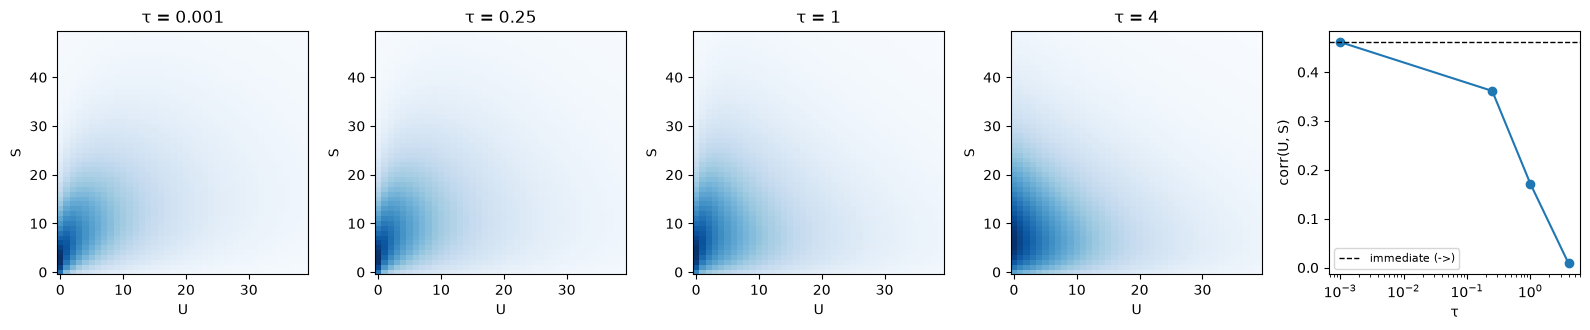

correlation with the immediate reaction: 0.462


,tau,max |ΔP(U)| vs ->,max |ΔP(S)| vs ->,"corr(U, S)"
0,0.001,0.0,0.0,0.4614
1,0.250,0.0,0.0,0.3615
2,1.000,0.0,0.0,0.1715
3,4.000,0.0,0.0,0.0086


In [25]:
import pandas as pd

net_delay = ReactionNetwork('0 -> B x U => S -> 0', normalize_production_rate=True)
print(net_delay)
print('\nall_params:', net_delay.all_params, '  (B, inverse delay, commitment rate, degradation rate)')

m_delay = CMEModel('Custom', 'None', network='0 -> B x U => S -> 0', normalize_production_rate=True)
m_now = CMEModel('Custom', 'None', network='0 -> B x U -> S -> 0', normalize_production_rate=True)
B_d, k_commit, gamma_d = 5.0, 1.0, 0.5
LIM_D = [40, 50]
pss_now = m_now.eval_model_pss(np.log10([B_d, k_commit, gamma_d]), LIM_D)

def corr(pss):
    u = np.arange(pss.shape[0])[:, None]; s = np.arange(pss.shape[1])[None, :]
    mu_u, mu_s = (pss * u).sum(), (pss * s).sum()
    cov = (pss * (u - mu_u) * (s - mu_s)).sum()
    return cov / np.sqrt((pss * (u - mu_u) ** 2).sum() * (pss * (s - mu_s) ** 2).sum())

taus = [0.001, 0.25, 1.0, 4.0]
fig, axes = plt.subplots(1, len(taus) + 1, figsize=(16, 3.4))
rows = []
for ax, tau in zip(axes, taus):
    pss = m_delay.eval_model_pss(np.log10([B_d, 1 / tau, k_commit, gamma_d]), LIM_D)
    rows.append((tau, np.abs(pss.sum(1) - pss_now.sum(1)).max(), np.abs(pss.sum(0) - pss_now.sum(0)).max(), corr(pss)))
    ax.imshow(pss.T, origin='lower', aspect='auto', cmap='Blues', norm=mcolors.PowerNorm(gamma=0.4, vmin=0))
    ax.set_title(f'τ = {tau:g}'); ax.set_xlabel('U'); ax.set_ylabel('S')
tab = pd.DataFrame(rows, columns=['tau', 'max |ΔP(U)| vs ->', 'max |ΔP(S)| vs ->', 'corr(U, S)'])
axes[-1].plot(tab['tau'], tab['corr(U, S)'], 'o-'); axes[-1].axhline(corr(pss_now), color='k', ls='--', lw=1, label='immediate (->)')
axes[-1].set_xscale('log'); axes[-1].set_xlabel('τ'); axes[-1].set_ylabel('corr(U, S)'); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/network_delay_joint.png', dpi=130); plt.show()
print(f'correlation with the immediate reaction: {corr(pss_now):.3f}')
tab.round(4)


The marginals agree with the immediate network to the integrator's tolerance at every delay, while the correlation between unspliced and spliced counts falls from its `->` value of 0.46 to almost nothing once $\tau$ exceeds the lifetimes of the two species. At $\tau \to 0$ the delayed network reproduces the immediate one exactly, which is the parity the test suite checks.

### 9.1 Can the data see the delay?


In [26]:
r = m_delay.check_identifiability(np.log10([B_d, 1.0, k_commit, gamma_d]), LIM_D, warn=False)
print('relative singular values:', ' '.join(f'{v:.1e}' for v in r['singular_values']))
print('least-constrained direction:', {k: round(v, 2) for k, v in zip(r['param_names'], r['directions'][-1])})


relative singular values: 1.0e+00 6.6e-01 1.8e-01 8.3e-02
least-constrained direction: {'B': np.float64(-0.01), 'tauinv0': np.float64(-1.0), 'k1': np.float64(0.01), 'k2': np.float64(0.08)}


The delay is the least-constrained direction, and it is `tauinv0` alone, but its singular value sits well above the threshold: the correlation carries it, as the plots above showed, and the rank test calls the network identifiable at a delay of one time unit.

### 9.2 A panel of genes: when is a delay worth having?

Whether a particular gene *needs* a delay is a question to ask of many genes at once, not of a hand-picked one. The delayed network nests the immediate one ($\tau \to 0$ recovers `->`), so for every gene the two fits can be compared by a likelihood ratio: with the divergence reported per cell, $2 N_{cells}\,(\mathrm{KLD}_{imm} - \mathrm{KLD}_{del})$ is twice the log-likelihood gain from the extra parameter. Under the no-delay null that statistic follows a $\chi^2_1$ halved at zero (the null sits on the boundary of the parameter box), so its 5% critical value is 2.71 rather than 3.84.

We fit both networks to 40 genes of the Allen GABAergic data used in the sequencing-noise notebook. The immediate network is the built-in `Bursty` model, which starts every gene at its moment estimate; the custom network has no moment estimator, so it starts from the middle of its box and we give it three random restarts. One check costs nothing and catches optimizer failures: a nested model can never fit worse than the model it contains, so a delayed divergence above the immediate one marks a fit that ended in the wrong basin, and those genes are refitted with more restarts.


In [27]:
import zlib, functools
from pathlib import Path
from monod.inference import search_result_from_uns
import monod.inference as inference_module
inference_module.tqdm = functools.partial(inference_module.tqdm, disable=True)   # no progress bars in the saved notebook

GABA = 'example_h5ad/gaba_example.h5ad'
if not os.path.exists(GABA) and os.path.isdir('monod_examples/sample_data/gaba_anndata'):
    # the example repository ships the h5ad as zlib-compressed chunks
    chunks = sorted(Path('monod_examples/sample_data/gaba_anndata').glob('chunk_*.gz'))
    open(GABA, 'wb').write(b''.join(zlib.decompress(open(f, 'rb').read()) for f in chunks))
with warnings.catch_warnings():
    warnings.simplefilter('ignore', UserWarning)          # duplicate gene names in the file
    gaba_raw = ad.read_h5ad(GABA)
gaba_raw.var_names_make_unique()

N_PANEL = 40
GP_PANEL = {'max_iterations': 100, 'num_restarts': 3, 'num_gene_cores': 8}
m_imm = CMEModel('Bursty', 'None')                       # the immediate network, with a moment estimator to start from
m_del = CMEModel('Custom', 'None', network='0 -> B x U => S -> 0', normalize_production_rate=True)

t0 = time.time()
warnings.simplefilter('ignore', IdentifiabilityWarning)   # the table below reports the flags gene by gene
imm = perform_inference(gaba_raw, m_imm, n_genes=N_PANEL, viz=False, exclude_sigma=False,
                        gradient_params=GP_PANEL, dataset_string='panel_immediate', seed=1, num_cores=8)
dly = perform_inference(gaba_raw, m_del, n_genes=N_PANEL, viz=False, exclude_sigma=False, modality_name_dict=MAP,
                        gradient_params=GP_PANEL, dataset_string='panel_delayed', seed=1, num_cores=8)
assert list(imm.var_names) == list(dly.var_names)
print(f'{N_PANEL} genes, {imm.n_obs} cells: both fits with standard errors in {time.time() - t0:.0f} s')

def panel_table(imm, dly):
    sr_i = search_result_from_uns(imm.uns['search_result']); sr_d = search_result_from_uns(dly.uns['search_result'])
    P_i, P_d = np.asarray(sr_i.phys_optimum), np.asarray(sr_d.phys_optimum)
    t = pd.DataFrame({'kld_immediate': np.asarray(sr_i.klds).ravel(), 'kld_delayed': np.asarray(sr_d.klds).ravel(),
                      'tau': 10 ** -P_d[:, 1], 'tau_x_k1': 10 ** (P_d[:, 2] - P_d[:, 1]),
                      'sigma_log10_tauinv': np.asarray(sr_d.sigma)[:, 1], 'sigma_unreliable': np.asarray(sr_d.sigma_fail, dtype=bool),
                      'at_no_delay_bound': np.isclose(P_d[:, 1], m_del.bio_bounds['phys_ub'][1])}, index=imm.var_names)
    t['LR'] = 2 * imm.n_obs * (t.kld_immediate - t.kld_delayed)
    return t, P_i, P_d

panel, P_imm, P_del = panel_table(imm, dly)
stuck = list(panel.index[panel.LR < -1])
if stuck:
    print(f'delayed fit worse than the immediate one for {stuck}: refitting with ten restarts')
    redo = perform_inference(gaba_raw, m_del, genes_to_fit=stuck, n_genes=len(stuck), viz=False, exclude_sigma=False, modality_name_dict=MAP,
                             gradient_params={**GP_PANEL, 'num_restarts': 10}, dataset_string='panel_delayed_redo', seed=2, num_cores=8)
    sr_r = search_result_from_uns(redo.uns['search_result'])
    for k, g in enumerate(redo.var_names):
        j = list(dly.var_names).index(g)
        P_del[j] = np.asarray(sr_r.phys_optimum)[k]
        panel.loc[g, ['kld_delayed', 'tau', 'tau_x_k1', 'sigma_log10_tauinv', 'sigma_unreliable']] = [
            float(np.asarray(sr_r.klds).ravel()[k]), 10 ** -P_del[j, 1], 10 ** (P_del[j, 2] - P_del[j, 1]),
            float(np.asarray(sr_r.sigma)[k, 1]), bool(np.asarray(sr_r.sigma_fail)[k])]
        panel.loc[g, 'at_no_delay_bound'] = bool(np.isclose(P_del[j, 1], m_del.bio_bounds['phys_ub'][1]))
    panel['LR'] = 2 * imm.n_obs * (panel.kld_immediate - panel.kld_delayed)

CRIT = 2.71
print(f'delay preferred (LR > {CRIT}): {(panel.LR > CRIT).sum()} of {len(panel)} genes; '
      f'at the no-delay bound: {panel.at_no_delay_bound.sum()}; standard error on tauinv flagged: {panel.sigma_unreliable.sum()}')
display(panel.sort_values('LR', ascending=False).round(3).head(12))


40 genes, 728 cells: both fits with standard errors in 250 s
delayed fit worse than the immediate one for ['Nsd3']: refitting with ten restarts


delay preferred (LR > 2.71): 13 of 40 genes; at the no-delay bound: 10; standard error on tauinv flagged: 13


,kld_immediate,kld_delayed,tau,tau_x_k1,sigma_log10_tauinv,sigma_unreliable,at_no_delay_bound,LR
Efna5,0.627,0.566,0.336,0.460,0.070,False,False,88.778
Yjefn3,0.417,0.391,0.274,1.755,0.066,False,False,38.164
Fhit,0.088,0.068,1.670,2.332,0.155,False,False,30.244
Shisa9,0.687,0.675,0.077,0.172,0.139,False,False,18.028
Ercc6l2,0.026,0.015,3.170,3.216,0.533,False,False,15.809
Tm2d1,0.055,0.048,1.706,1.337,0.256,False,False,9.130
Slc49a4,0.045,0.040,0.915,0.762,0.203,False,False,7.773
Fam204a,0.022,0.018,1.232,1.455,0.305,False,False,6.402
Hace1,0.066,0.062,0.948,0.384,0.210,False,False,5.771
Ppp6c,0.080,0.076,0.864,0.494,0.219,False,False,5.315


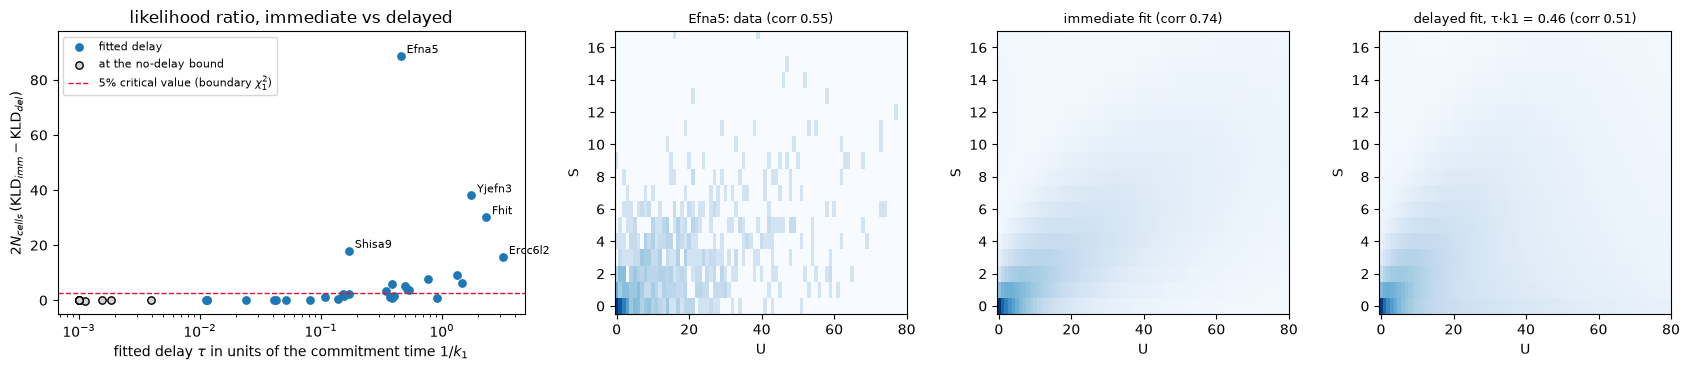

In [28]:
ok = panel.LR > -1
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={'width_ratios': [1.6, 1, 1, 1]})
ax = axes[0]
x = panel.tau_x_k1.clip(lower=1e-3)
free, bound = ok & ~panel.at_no_delay_bound, ok & panel.at_no_delay_bound
ax.scatter(x[free], panel.LR[free], c='tab:blue', s=28, label='fitted delay')
ax.scatter(x[bound], panel.LR[bound], c='lightgray', edgecolor='k', s=28, label='at the no-delay bound')
ax.axhline(CRIT, color='crimson', ls='--', lw=1, label=r'5% critical value (boundary $\chi^2_1$)')
ax.set_xscale('log'); ax.set_ylim(-5, panel.LR[ok].max() * 1.1)
ax.set_xlabel(r'fitted delay $\tau$ in units of the commitment time $1/k_1$'); ax.set_ylabel(r'$2 N_{cells}\,(\mathrm{KLD}_{imm} - \mathrm{KLD}_{del})$')
ax.set_title('likelihood ratio, immediate vs delayed'); ax.legend(fontsize=8, loc='upper left')
for g in panel.index[ok & (panel.LR > 15)]:
    ax.annotate(g, (x[g], panel.LR[g]), fontsize=8, xytext=(4, 2), textcoords='offset points')

# the gene with the strongest preference: data against the two fits
top = panel.index[ok][panel.LR[ok].argmax()]; gi = list(imm.var_names).index(top)
M_top = imm.uns['M'][:, gi].tolist()
U = np.asarray(gaba_raw[:, top].layers['unspliced'].todense()).ravel(); S = np.asarray(gaba_raw[:, top].layers['spliced'].todense()).ravel()
H, _, _ = np.histogram2d(U, S, bins=[np.arange(M_top[0] + 1), np.arange(M_top[1] + 1)]); H /= H.sum()
pss_imm_top = m_imm.eval_model_pss(P_imm[gi], M_top); pss_del_top = m_del.eval_model_pss(P_del[gi], M_top)
vmax = max(H.max(), pss_imm_top.max(), pss_del_top.max())
u_max, s_max = int(np.quantile(U, 0.995)) + 2, int(np.quantile(S, 0.995)) + 2     # show where the cells are
for a, Z, ttl in zip(axes[1:], (H, pss_imm_top, pss_del_top),
                     (f'{top}: data (corr {corr(H):.2f})', f'immediate fit (corr {corr(pss_imm_top):.2f})',
                      f'delayed fit, τ·k1 = {panel.tau_x_k1[top]:.2f} (corr {corr(pss_del_top):.2f})')):
    a.imshow(Z.T, origin='lower', aspect='auto', cmap='Blues', norm=mcolors.PowerNorm(gamma=0.4, vmin=0, vmax=vmax))
    a.set_title(ttl, fontsize=9); a.set_xlabel('U'); a.set_ylabel('S'); a.set_xlim(-0.5, u_max); a.set_ylim(-0.5, s_max)
plt.tight_layout(); plt.savefig('figures/network_delay_panel.png', dpi=120); plt.show()


Thirteen of the forty genes prefer a delay at the 5% level and ten run to the no-delay bound, with the rest in between; the flagged standard errors are almost all genes whose delay the data do not constrain at all (the error on $\log_{10}$`tauinv` is wider than the box), which is the honest answer for a gene whose unspliced and spliced counts are nearly independent. Where a delay is preferred it is of the order of the commitment time, a few tenths to a few times $1/k_1$: long enough to matter for the joint distribution, too short to be noticed in either marginal.

The strongest case, Efna5, shows what the delay buys. The immediate network reproduces the two marginals but overshoots the correlation between unspliced and spliced counts (0.74 against 0.55 in the data); the delayed network matches it with a delay of about half the commitment time, and the divergence falls by a tenth. The refitted gene (Nsd3) ends within a likelihood ratio of one of its immediate fit once the optimizer leaves the wrong basin: with no moment estimator to start from, custom networks need a few restarts, and the nested-model inequality is the cheap way to find the fits that did not get them.

Three qualifications. These are fits without a sequencing-noise model to 728 cells of one dataset, so the counts are small and the likelihood ratios modest; the test treats $2 N_{cells}\,\Delta\mathrm{KLD}$ as a likelihood ratio, which holds for independent cells; and the delay is measured in the time unit set by normalising the production rate to one, so compare delays to the other rates of the same gene rather than between genes. Whether a delayed network is worth adopting is a question for the joint distribution across many genes, and this is the shape of the answer: a minority of genes with a clear preference, most of them indifferent, and a figure that shows which is which.
